<a href="https://colab.research.google.com/github/cero1979/DescensoGrad/blob/main/descenso_gradiente_2_variables_autocontenido.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Descenso del gradiente con **dos variables**
## Decisiones de marketing e inventario: una clase visual de 2 horas

### Pregunta guía
Una empresa debe decidir simultáneamente **cuánto invertir en publicidad** y **cuánto inventario de seguridad mantener**. ¿Cómo puede mejorar ambas decisiones paso a paso?

### Metas de aprendizaje
- Interpretar un mapa de costos como un paisaje con valles.
- Entender que el gradiente tiene **dos componentes**, una por cada decisión.
- Hacer las cuentas de una actualización completa.
- Leer una trayectoria en curvas de nivel y en una superficie 3D.
- Explicar por qué el tamaño del paso puede ser lento, prudente o inestable.

> **Idea para recordar:** el gradiente es una brújula con dos instrucciones: “corrige un poco `x` y corrige un poco `y`”.

**Ruta de 120 minutos:** 0–10 apertura; 10–25 paisaje; 25–40 dos señales; 40–68 caso y cuentas; 68–73 pausa; 73–90 animaciones; 90–105 tamaño del paso; 105–115 actividad; 115–120 cierre.

In [1]:
import tempfile
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 12})
print("Listo: trabajaremos con publicidad x e inventario y.")

Listo: trabajaremos con publicidad x e inventario y.


# 1. Del problema de una variable al problema real (0–25 min)

Con una sola decisión dibujamos una curva. Con dos decisiones dibujamos una superficie:

- eje `x`: inversión semanal en publicidad;
- eje `y`: inventario de seguridad;
- altura: costo semanal total.

Un punto `(x, y)` es una **política completa** de la empresa. Moverse significa cambiar las dos decisiones.

### Pregunta de apertura
Si aumentar `x` reduce el costo pero aumentar `y` lo aumenta, ¿podemos corregir las dos decisiones a la vez? **Sí: necesitamos dos señales, una para cada eje.**

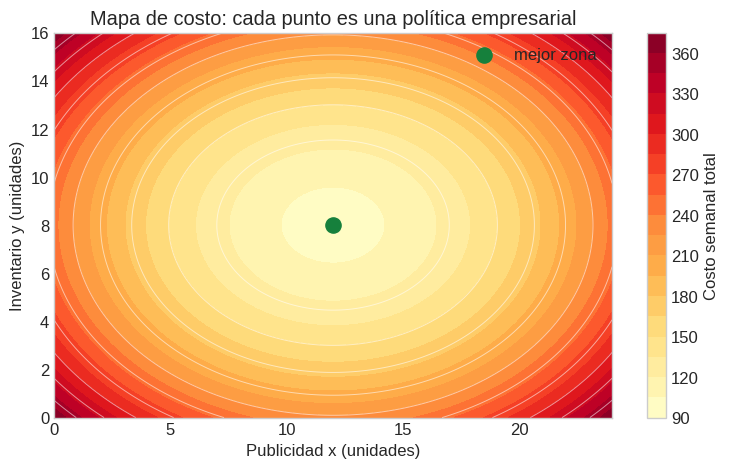

In [2]:
x = np.linspace(0, 24, 160)
y = np.linspace(0, 16, 140)
X, Y = np.meshgrid(x, y)
def costo(x, y):
    return (x - 12)**2 + 2*(y - 8)**2 + 100
Z = costo(X, Y)

fig, ax = plt.subplots()
cont = ax.contourf(X, Y, Z, levels=20, cmap="YlOrRd")
ax.contour(X, Y, Z, levels=12, colors="white", alpha=.55, linewidths=.7)
ax.scatter([12], [8], s=120, c="#16803c", label="mejor zona")
ax.set(xlabel="Publicidad x (unidades)", ylabel="Inventario y (unidades)",
       title="Mapa de costo: cada punto es una política empresarial")
ax.legend()
fig.colorbar(cont, ax=ax, label="Costo semanal total")
plt.show()

# 2. La brújula de dos componentes (25–40 min)

El modelo didáctico será:

$$
J(x,y)=(x-12)^2+2(y-8)^2+100.
$$

El equipo analítico entrega las dos señales de inclinación:

$$
\frac{\partial J}{\partial x}=2(x-12),\qquad
\frac{\partial J}{\partial y}=4(y-8).
$$

No pedimos demostrar estas expresiones. Las interpretamos:

| Señal | Pregunta gerencial |
|---|---|
| `g_x` | ¿hacia qué lado ajustar publicidad? |
| `g_y` | ¿hacia qué lado ajustar inventario? |
| `(g_x,g_y)` | ¿qué dirección conjunta reduce el costo? |

La actualización completa es:

$$
\boxed{x_{nuevo}=x-\eta g_x,\qquad y_{nuevo}=y-\eta g_y.}
$$

El signo menos significa “moverse contra la subida”. No se suman las dos señales: cada una corrige su propia decisión.

## Derivadas parciales sin miedo

Una derivada parcial responde una pregunta concreta: **¿qué ocurre con el costo si cambio una sola decisión y mantengo la otra fija?**

Para publicidad, mantenemos `y` quieta y miramos qué pasa al cambiar `x`:

$$\nabla_x J=\frac{\partial J}{\partial x}=2(x-12).$$

Para inventario, mantenemos `x` quieta y miramos qué pasa al cambiar `y`:

$$\nabla_y J=\frac{\partial J}{\partial y}=4(y-8).$$

En `(x,y)=(2,2)`, las dos señales son `-20` y `-24`. El signo negativo significa que aumentar esa decisión reduce el costo localmente. Juntas forman el gradiente:

$$\nabla J(2,2)=\left(\frac{\partial J}{\partial x},\frac{\partial J}{\partial y}\right)=(-20,-24).$$

No necesitamos demostrar formalmente las reglas: basta distinguir qué variable se mueve y cuál se mantiene fija. Cada componente se usa en su propia actualización.


## Ruta general del algoritmo

El descenso del gradiente se resume con una sola fórmula vectorial:

$$
\boxed{\boldsymbol{\theta}_{k+1}
=\boldsymbol{\theta}_k-\eta\,\nabla J(\boldsymbol{\theta}_k)}
$$

En dos variables, $\boldsymbol{\theta}_k=(x_k,y_k)$ y la misma fórmula significa:

$$
\begin{aligned}
x_{k+1} &= x_k-\eta\,\frac{\partial J}{\partial x}(x_k,y_k),\\
y_{k+1} &= y_k-\eta\,\frac{\partial J}{\partial y}(x_k,y_k).
\end{aligned}
$$

### Receta aplicable a cualquier problema

1. **Definir las decisiones:** identificar qué representan $x$ e $y$.
2. **Definir el objetivo:** construir una función $J(x,y)$ que mida costo, error o pérdida.
3. **Elegir el inicio:** seleccionar $(x_0,y_0)$ y un tamaño de paso $\eta$.
4. **Medir las pendientes:** calcular $\partial J/\partial x$ y $\partial J/\partial y$.
5. **Actualizar juntas las decisiones:** aplicar las dos ecuaciones anteriores.
6. **Verificar:** comprobar si $J(x_{k+1},y_{k+1})<J(x_k,y_k)$.
7. **Repetir o detener:** continuar hasta que la mejora sea pequeña o se alcance el límite de rondas.

> La **ruta** es la sucesión $(x_0,y_0),(x_1,y_1),(x_2,y_2),\ldots$. Cada punto es una política empresarial y cada segmento es una corrección.


## Laboratorio interactivo: cambie la ruta

Mueva los sliders y observe cómo cambia la trayectoria roja:

- **Inicio $x_0$:** publicidad inicial.
- **Inicio $y_0$:** inventario inicial.
- **Paso $\eta$:** intensidad de cada corrección.
- **Iteraciones:** cantidad de rondas.

Pruebe primero $\eta=0.10$, luego $\eta=0.45$ y finalmente $\eta=0.50$. Observe cuándo la ruta avanza suavemente, cuándo oscila y cuándo deja de acercarse al mínimo.


In [3]:
# Esta celda es autocontenida: puede ejecutarse sola.
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

def costo_interactivo(x, y):
    return (x - 12) ** 2 + 2 * (y - 8) ** 2 + 100

x_mapa = np.linspace(0, 24, 160)
y_mapa = np.linspace(0, 16, 140)
X_mapa, Y_mapa = np.meshgrid(x_mapa, y_mapa)
Z_mapa = costo_interactivo(X_mapa, Y_mapa)

def mostrar_ruta(x0=2.0, y0=2.0, eta=0.10, iteraciones=8):
    x_actual, y_actual = float(x0), float(y0)
    ruta_x, ruta_y = [x_actual], [y_actual]

    for _ in range(int(iteraciones)):
        parcial_x = 2 * (x_actual - 12)
        parcial_y = 4 * (y_actual - 8)
        x_actual = x_actual - eta * parcial_x
        y_actual = y_actual - eta * parcial_y
        ruta_x.append(x_actual)
        ruta_y.append(y_actual)

    ruta_x = np.array(ruta_x)
    ruta_y = np.array(ruta_y)
    costos = costo_interactivo(ruta_x, ruta_y)

    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.contourf(
        X_mapa, Y_mapa, Z_mapa, levels=22, cmap="YlOrRd", alpha=0.9
    )
    ax.contour(
        X_mapa, Y_mapa, Z_mapa, levels=12, colors="white", alpha=0.55
    )
    ax.plot(
        ruta_x,
        ruta_y,
        "o-",
        color="#0057b8",
        linewidth=2.5,
        markersize=6,
        label="Ruta del algoritmo",
    )
    ax.scatter(
        [ruta_x[0]], [ruta_y[0]], s=120, color="#d62828",
        zorder=5, label="Inicio"
    )
    ax.scatter(
        [12], [8], s=140, color="#16803c", marker="*",
        zorder=5, label="Mínimo (12, 8)"
    )

    for k, (px, py) in enumerate(zip(ruta_x, ruta_y)):
        if 0 <= px <= 24 and 0 <= py <= 16:
            ax.annotate(
                str(k),
                (px, py),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=9,
            )

    ax.set(
        xlim=(0, 24),
        ylim=(0, 16),
        xlabel="Publicidad x",
        ylabel="Inventario y",
        title=(
            f"Ruta con η={eta:.2f}: costo "
            f"{costos[0]:.2f} → {costos[-1]:.2f}"
        ),
    )
    ax.legend(loc="upper right")
    plt.show()

    tendencia = "bajó" if costos[-1] < costos[0] else "subió"
    print(
        f"Inicio: ({ruta_x[0]:.2f}, {ruta_y[0]:.2f}) | "
        f"Final: ({ruta_x[-1]:.2f}, {ruta_y[-1]:.2f}) | "
        f"El costo {tendencia}: {costos[0]:.2f} → {costos[-1]:.2f}"
    )

x0_slider = widgets.FloatSlider(
    value=2.0, min=0.0, max=24.0, step=0.5,
    description="Inicio x₀", continuous_update=False,
)
y0_slider = widgets.FloatSlider(
    value=2.0, min=0.0, max=16.0, step=0.5,
    description="Inicio y₀", continuous_update=False,
)
eta_slider = widgets.FloatSlider(
    value=0.10, min=0.01, max=0.50, step=0.01,
    description="Paso η", readout_format=".2f", continuous_update=False,
)
iter_slider = widgets.IntSlider(
    value=8, min=1, max=20, step=1,
    description="Iteraciones", continuous_update=False,
)

controles = widgets.VBox([
    widgets.HBox([x0_slider, y0_slider]),
    widgets.HBox([eta_slider, iter_slider]),
])
salida = widgets.interactive_output(
    mostrar_ruta,
    {
        "x0": x0_slider,
        "y0": y0_slider,
        "eta": eta_slider,
        "iteraciones": iter_slider,
    },
)
display(controles, salida)


Output()

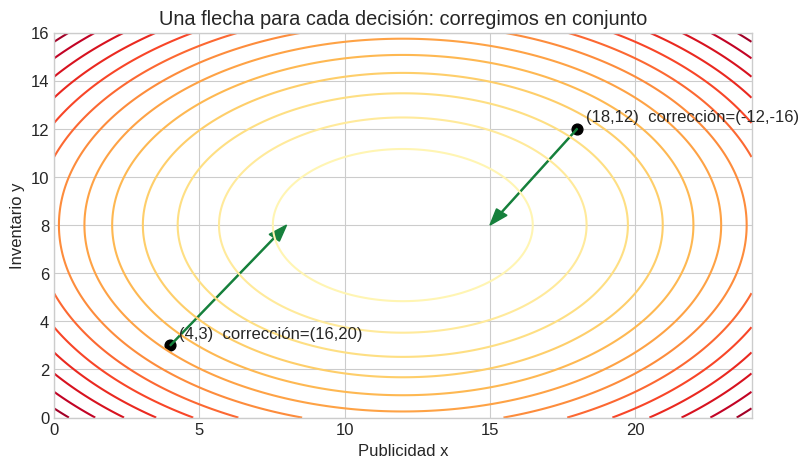

In [4]:
# Dos puntos para leer la dirección sin hacer teoría
puntos = [(4, 3), (18, 12)]
fig, ax = plt.subplots()
ax.contour(X, Y, Z, levels=14, cmap="YlOrRd")
for px, py in puntos:
    gx, gy = 2*(px-12), 4*(py-8)
    ax.scatter(px, py, c="black", s=60)
    ax.arrow(px, py, -gx/4, -gy/4, width=.04, head_width=.45,
             color="#16803c", length_includes_head=True)
    ax.text(px+.3, py+.3, f"({px},{py})  corrección=({-gx:.0f},{-gy:.0f})")
ax.set(xlabel="Publicidad x", ylabel="Inventario y",
       title="Una flecha para cada decisión: corregimos en conjunto")
plt.show()

# 3. Caso empresarial y primera cuenta completa (40–55 min)

## Contexto

Una cadena minorista desea reducir el costo semanal de **campañas desperdiciadas + inventario de seguridad mal ajustado**. El modelo resume el costo esperado:

$$
J(x,y)=(x-12)^2+2(y-8)^2+100.
$$

La empresa empieza con:

$$
(x_0,y_0)=(2,2),\qquad \eta=0.10.
$$

### Ronda 0: escriba una línea a la vez

$$
g_x=2(2-12)=-20,\qquad g_y=4(2-8)=-24.
$$

Ambas señales son negativas: conviene aumentar **publicidad e inventario**.

$$
x_1=2-0.10(-20)=\boxed{4}
$$
$$
y_1=2-0.10(-24)=\boxed{4.4}
$$

Costo antes:

$$
J(2,2)=(-10)^2+2(-6)^2+100=100+72+100=\boxed{272}.
$$

Costo después:

$$
J(4,4.4)=(-8)^2+2(-3.6)^2+100
=64+25.92+100=\boxed{189.92}.
$$

**Lectura gerencial:** una sola ronda redujo el costo estimado en `272−189.92=82.08` unidades.

In [5]:
eta = 0.10
actual = np.array([2.0, 2.0])
historia = []
for k in range(8):
    gx, gy = 2*(actual[0]-12), 4*(actual[1]-8)
    nueva = actual - eta*np.array([gx, gy])
    historia.append((k, actual[0], actual[1], gx, gy, nueva[0], nueva[1],
                     costo(actual[0], actual[1])))
    actual = nueva

print(" k |   x     y   |  gx     gy   | x nueva y nueva |    costo")
print("-"*64)
for fila in historia:
    k, px, py, gx, gy, nx, ny, j = fila
    print(f"{k:2d} | {px:5.2f} {py:5.2f} | {gx:6.2f} {gy:6.2f} |"
          f" {nx:7.2f} {ny:7.2f} | {j:8.2f}")

 k |   x     y   |  gx     gy   | x nueva y nueva |    costo
----------------------------------------------------------------
 0 |  2.00  2.00 | -20.00 -24.00 |    4.00    4.40 |   272.00
 1 |  4.00  4.40 | -16.00 -14.40 |    5.60    5.84 |   189.92
 2 |  5.60  5.84 | -12.80  -8.64 |    6.88    6.70 |   150.29
 3 |  6.88  6.70 | -10.24  -5.18 |    7.90    7.22 |   129.57
 4 |  7.90  7.22 |  -8.19  -3.11 |    8.72    7.53 |   117.99
 5 |  8.72  7.53 |  -6.55  -1.87 |    9.38    7.72 |   111.17
 6 |  9.38  7.72 |  -5.24  -1.12 |    9.90    7.83 |   107.03
 7 |  9.90  7.83 |  -4.19  -0.67 |   10.32    7.90 |   104.45


## Rondas siguientes: el patrón, no la memorización

En la segunda ronda la nueva decisión es `(4, 4.4)`:

$$
g_x=2(4-12)=-16,\qquad g_y=4(4.4-8)=-14.4.
$$
$$
x_2=4-0.10(-16)=5.6,\qquad
y_2=4.4-0.10(-14.4)=5.84.
$$

En la tercera:

$$
g_x=2(5.6-12)=-12.8,\qquad
g_y=4(5.84-8)=-8.64,
$$
$$
(x_3,y_3)=(5.6+1.28,\;5.84+0.864)
=(\boxed{6.88},\boxed{6.704}).
$$

Observe que las dos correcciones se hacen simultáneamente y que cada señal va disminuyendo al acercarse a `(12,8)`.

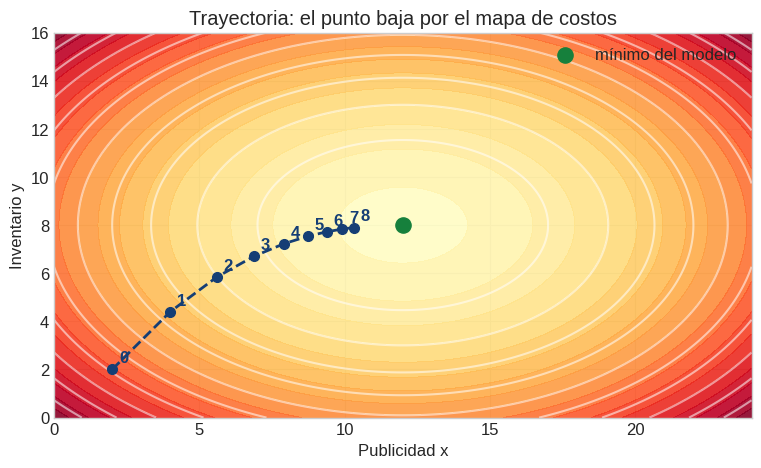

In [6]:
xs = np.array([r[1] for r in historia] + [historia[-1][5]])
ys = np.array([r[2] for r in historia] + [historia[-1][6]])
fig, ax = plt.subplots()
ax.contourf(X, Y, Z, levels=20, cmap="YlOrRd", alpha=.9)
ax.contour(X, Y, Z, levels=12, colors="white", alpha=.55)
ax.plot(xs, ys, "o--", color="#153e75", linewidth=2, markersize=7)
for k, (px, py) in enumerate(zip(xs, ys)):
    ax.annotate(str(k), (px, py), xytext=(5, 5), textcoords="offset points",
                color="#153e75", weight="bold")
ax.scatter([12], [8], c="#16803c", s=120, label="mínimo del modelo")
ax.set(xlabel="Publicidad x", ylabel="Inventario y",
       title="Trayectoria: el punto baja por el mapa de costos")
ax.legend()
plt.show()

# 4. Animación 1: la trayectoria sobre el mapa (73–82 min)

La siguiente salida es un **GIF incrustado**, no solo una figura estática. Al ejecutar la celda debe aparecer un reproductor visual en el cuaderno. Mire cómo el punto rojo se acerca al centro de las elipses.

Preguntas durante la animación:
1. ¿Qué variable cambia más al principio: `x` o `y`?
2. ¿Por qué el camino no es una línea recta?
3. ¿Qué significa entrar en curvas de nivel más interiores?

Si su visor no reproduce el GIF, descargue el cuaderno o ábralo en Jupyter/VS Code: la celda también deja una secuencia numerada de las posiciones.

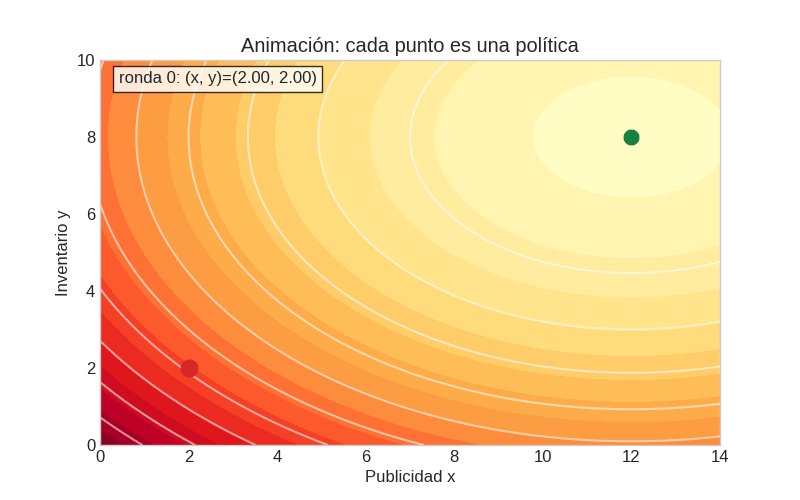

In [9]:
# Animación visible: GIF embebido en la salida del notebook
frames = list(zip(xs, ys))
fig, ax = plt.subplots(figsize=(8, 5))
ax.contourf(X, Y, Z, levels=20, cmap="YlOrRd")
ax.contour(X, Y, Z, levels=12, colors="white", alpha=.55)
ax.scatter([12], [8], c="#16803c", s=110)
point, = ax.plot([], [], "o", color="#d62828", markersize=12)
trail, = ax.plot([], [], "-", color="#d62828", alpha=.75, linewidth=2)
label = ax.text(.03, .94, "", transform=ax.transAxes,
                bbox={"facecolor": "white", "alpha": .8})
ax.set(xlim=(0, 14), ylim=(0, 10), xlabel="Publicidad x",
       ylabel="Inventario y", title="Animación: cada punto es una política")

def draw(i):
    path = np.array(frames[:i+1])
    point.set_data([path[-1, 0]], [path[-1, 1]])
    trail.set_data(path[:, 0], path[:, 1])
    label.set_text(f"ronda {i}: (x, y)=({path[-1,0]:.2f}, {path[-1,1]:.2f})")
    return point, trail, label

anim = FuncAnimation(fig, draw, frames=len(frames), interval=650, blit=True)
with tempfile.NamedTemporaryFile(suffix=".gif") as archivo_gif:
    anim.save(archivo_gif.name, writer=PillowWriter(fps=2))
    plt.close(fig)
    display(Image(filename=archivo_gif.name, format="gif"))

# 5. Animación 2: bajar una superficie 3D (82–90 min)

La misma historia puede verse como una montaña. La altura es el costo `J(x,y)`.

- el punto rojo empieza alto;
- cada salto usa las dos señales;
- la altura disminuye;
- el valle está en `(12,8)`, con costo base 100.

Esta visualización hace explícito por qué hablamos de **descenso**.

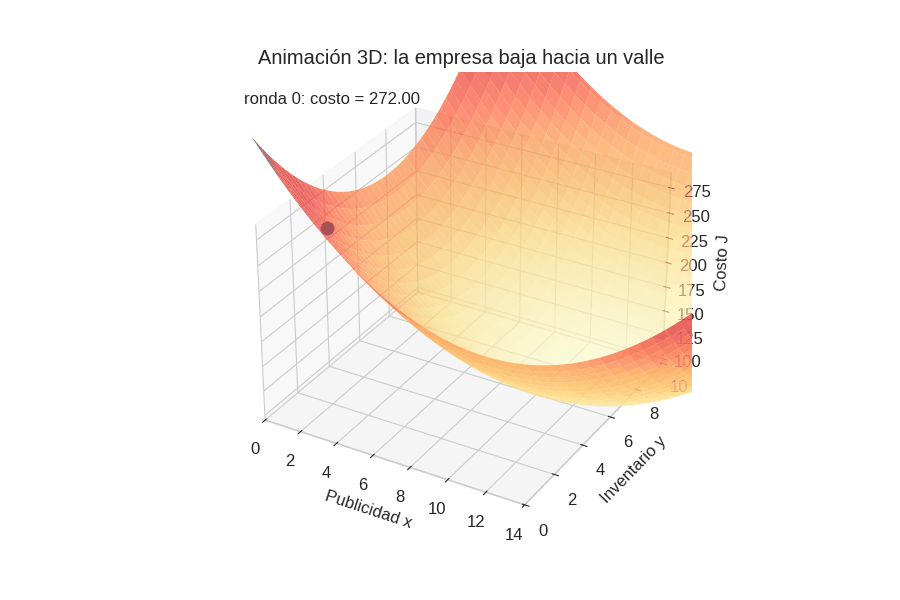

In [11]:
# Segunda animación visible: descenso sobre la superficie 3D
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(X, Y, Z, cmap="YlOrRd", alpha=.65, linewidth=0)
ax.set(xlim=(0, 14), ylim=(0, 10), zlim=(95, 290),
       xlabel="Publicidad x", ylabel="Inventario y", zlabel="Costo J",
       title="Animación 3D: la empresa baja hacia un valle")
dot, = ax.plot([], [], [], "o", color="#d62828", markersize=9)
caption = ax.text2D(.03, .93, "", transform=ax.transAxes)

def draw_surface(i):
    px, py = frames[i]
    dot.set_data_3d([px], [py], [costo(px, py)])
    caption.set_text(f"ronda {i}: costo = {costo(px, py):.2f}")
    return dot, caption

anim3d = FuncAnimation(fig, draw_surface, frames=len(frames),
                       interval=700, blit=False)
with tempfile.NamedTemporaryFile(suffix=".gif") as archivo_gif_3d:
    anim3d.save(archivo_gif_3d.name, writer=PillowWriter(fps=2))
    plt.close(fig)
    display(Image(filename=archivo_gif_3d.name, format="gif"))

# 6. Tamaño del paso y actividad final (90–115 min)

Compare tres políticas:

- `η=0.03`: muy prudente, pero tarda;
- `η=0.10`: estable y razonable para este ejemplo;
- `η=0.30`: reacciona demasiado y puede oscilar o alejarse.

La comparación importa porque en la empresa una corrección exagerada de publicidad o inventario también puede generar oscilaciones.

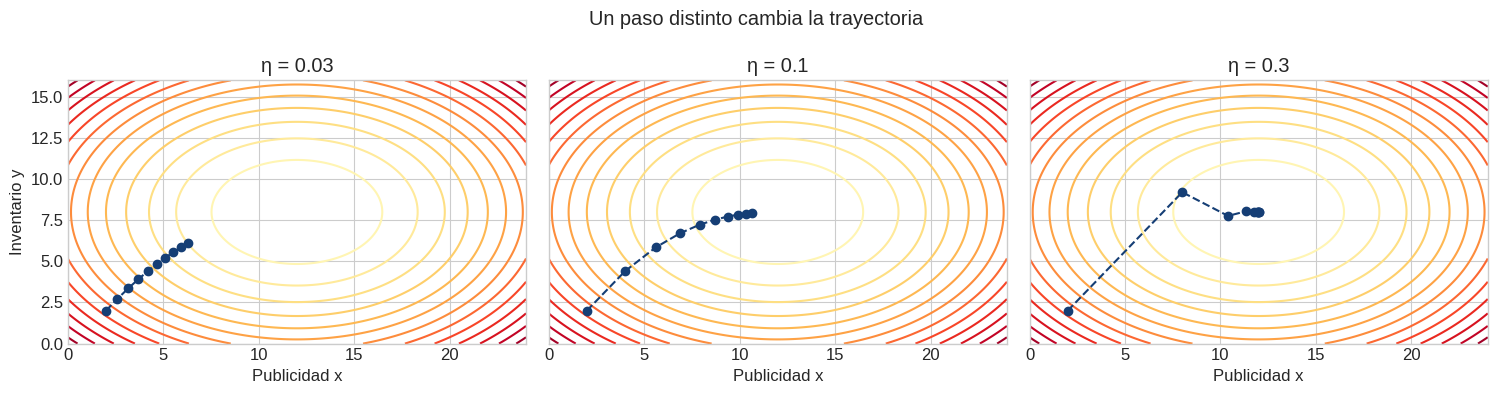

In [12]:
tasas = [0.03, 0.10, 0.30]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, tasa in zip(axes, tasas):
    camino = [np.array([2., 2.])]
    for _ in range(9):
        p = camino[-1]
        g = np.array([2*(p[0]-12), 4*(p[1]-8)])
        camino.append(p - tasa*g)
    camino = np.array(camino)
    ax.contour(X, Y, Z, levels=14, cmap="YlOrRd")
    ax.plot(camino[:,0], camino[:,1], "o--", color="#153e75")
    ax.set_title(f"η = {tasa}")
    ax.set_xlabel("Publicidad x")
axes[0].set_ylabel("Inventario y")
fig.suptitle("Un paso distinto cambia la trayectoria")
fig.tight_layout()
plt.show()

## Actividad: comité de decisiones (105–115 min)

Cada equipo recibe la política actual `(x,y)=(18,3)` y `η=0.10`.

Completen sin computadora:

1. `g_x = 2(18−12) = ____`; ¿aumentar o reducir publicidad?
2. `g_y = 4(3−8) = ____`; ¿aumentar o reducir inventario?
3. `x_nuevo = 18 − 0.10(g_x) = ____`.
4. `y_nuevo = 3 − 0.10(g_y) = ____`.
5. Comparen `J(18,3)` y `J(x_nuevo,y_nuevo)`.
6. Escriban una recomendación de gerencia en una frase.

In [13]:
x0, y0, eta_equipo = 18., 3., .10
gx, gy = 2*(x0-12), 4*(y0-8)
x1, y1 = x0-eta_equipo*gx, y0-eta_equipo*gy
print(f"gx={gx:.1f}: reducir publicidad; gy={gy:.1f}: aumentar inventario")
print(f"x_nuevo = 18 - 0.10({gx:.1f}) = {x1:.1f}")
print(f"y_nuevo = 3 - 0.10({gy:.1f}) = {y1:.1f}")
print(f"J(18,3)={costo(x0,y0):.2f}; J({x1:.1f},{y1:.1f})={costo(x1,y1):.2f}")
print(f"Reducción estimada={costo(x0,y0)-costo(x1,y1):.2f}")

gx=12.0: reducir publicidad; gy=-20.0: aumentar inventario
x_nuevo = 18 - 0.10(12.0) = 16.8
y_nuevo = 3 - 0.10(-20.0) = 5.0
J(18,3)=186.00; J(16.8,5.0)=141.04
Reducción estimada=44.96


# 7. Cierre (115–120 min)

## Cinco ideas
1. Dos decisiones producen un mapa, no una línea.
2. El gradiente tiene una señal para `x` y otra para `y`.
3. Cada señal se usa en su propio eje.
4. El signo menos nos lleva contra la subida.
5. Repetimos y verificamos si el costo baja.

### Boleto de salida

> “En el caso empresarial, `g_x` significa ______ y `g_y` significa ______. El tamaño `η` controla ______.”

### Nota de alcance

Este modelo es deliberadamente simple. En una empresa real, el costo se estima con datos, puede haber restricciones y el mejor punto puede cambiar. El método es una herramienta para organizar mejoras, no una sustitución del juicio gerencial.